In [53]:
%pip install gymnasium "stable-baselines3[extra]" tqdm rich pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: C:\Users\Hridish Das\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [54]:
%pip install "tqdm<4.68"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: C:\Users\Hridish Das\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [55]:
%pip install "tqdm==4.67.1" rich

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: C:\Users\Hridish Das\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [56]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from stable_baselines3.common.callbacks import EvalCallback, BaseCallback, CallbackList
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common import callbacks as sb3_callbacks

from tqdm.auto import tqdm

# True only if SB3's own bar works (we use our own TqdmCallback, so False is fine)
PROGRESS_BAR = sb3_callbacks.tqdm is not None
print("SB3 progress bar available:", PROGRESS_BAR)

os.makedirs("data", exist_ok=True)
os.makedirs("artifacts/best", exist_ok=True)

SB3 progress bar available: True


In [57]:
#Config (one place for all settings)

In [58]:
LOOKBACK    = 60          # candles the agent sees
COST_BPS    = 10.0        # cost per unit of position change (10 bps = 0.10%)
EPISODE_LEN = 2000        # training episode length
TOTAL_STEPS = 500_000     # PPO training steps

Load dataset/ cleanning

In [59]:
CSV = Path(r"C:\Users\Hridish Das\Downloads\2017_2025_tf_5min_with_volume_data\BTCUSDT_5m_2017-09-01_to_2025-09-23.csv")
CLEAN = Path("data/clean.parquet")          # <- same name is used by the next section

candle_data = pd.read_csv(CSV)

if pd.api.types.is_numeric_dtype(candle_data["datetime"]):
    unit = "ms" if candle_data["datetime"].iloc[0] > 1e11 else "s"
    candle_data["datetime"] = pd.to_datetime(candle_data["datetime"], unit=unit, utc=True)
else:
    candle_data["datetime"] = pd.to_datetime(candle_data["datetime"], utc=True)

# Your first timestamp is 05:30 -> the file may be in IST (UTC+5:30), not UTC.
# If you confirm that, uncomment the next line so hour-of-day features are correct:
# candle_data["datetime"] = candle_data["datetime"] - pd.Timedelta(hours=5, minutes=30)

candle_data = (candle_data.sort_values("datetime")
                          .drop_duplicates("datetime", keep="last")
                          .set_index("datetime"))

candle_data["high"] = candle_data[["open", "close", "high"]].max(axis=1)
candle_data["low"]  = candle_data[["open", "close", "low"]].min(axis=1)

full_idx = pd.date_range(candle_data.index.min(), candle_data.index.max(),
                         freq="5min", tz="UTC")
candle_data = candle_data.reindex(full_idx)
candle_data["synthetic"] = candle_data["close"].isna()

prev_close = candle_data["close"].ffill()
for c_ in ("open", "high", "low", "close"):
    candle_data[c_] = candle_data[c_].fillna(prev_close)

# FIX: keep volume as float (astype("int64") was truncating 0.37 BTC -> 0)
candle_data["volume"] = candle_data["volume"].fillna(0).astype("float64")
candle_data = candle_data.dropna(subset=["close"])

assert (candle_data["low"]  <= candle_data[["open", "close"]].min(axis=1)).all()
assert (candle_data["high"] >= candle_data[["open", "close"]].max(axis=1)).all()

candle_data.to_parquet(CLEAN)

print(f"✅ saved {CLEAN}: {len(candle_data):,} rows "
      f"({candle_data['synthetic'].sum():,} synthetic, "
      f"{candle_data['synthetic'].mean()*100:.2f}%)")
print(f"   {candle_data.index.min()} → {candle_data.index.max()}")

✅ saved data\clean.parquet: 848,160 rows (1,715 synthetic, 0.20%)
   2017-09-01 05:30:00+00:00 → 2025-09-24 05:25:00+00:00


In [60]:
candle_data.head()

,open,high,low,close,volume,synthetic
2017-09-01 05:30:00+00:00,4689.89,4689.91,4689.89,4689.91,0.422439,False
2017-09-01 05:35:00+00:00,4725.00,4725.00,4725.00,4725.00,0.473560,False
2017-09-01 05:40:00+00:00,4731.12,4731.13,4701.10,4731.13,1.291685,False
2017-09-01 05:45:00+00:00,4703.02,4705.02,4703.02,4705.02,0.097104,False
2017-09-01 05:50:00+00:00,4710.02,4710.02,4706.06,4706.06,0.541234,False


In [61]:
candle_data.tail()

,open,high,low,close,volume,synthetic
2025-09-24 05:05:00+00:00,111990.26,112107.00,111986.95,112074.01,22.00322,False
2025-09-24 05:10:00+00:00,112074.01,112099.12,112052.00,112078.66,4.14013,False
2025-09-24 05:15:00+00:00,112078.67,112101.59,112074.82,112075.59,6.08186,False
2025-09-24 05:20:00+00:00,112075.59,112075.59,112000.00,112011.20,16.66664,False
2025-09-24 05:25:00+00:00,112011.20,112011.21,111981.43,111998.80,21.12678,False


In [62]:
candle_data.shape

(848160, 6)

In [63]:
candle_data.isnull().sum()

open         0
high         0
low          0
close        0
volume       0
synthetic    0
dtype: int64

In [64]:
# Sanity check: volume should now contain fractions, not only whole numbers
print(candle_data["volume"].dtype)
print(candle_data["volume"].describe())
print("share of non-integer volumes:", (candle_data["volume"] % 1 != 0).mean().round(3))

float64
count    848160.000000
mean        222.940333
std         386.409307
min           0.000000
25%          54.918076
50%         108.392532
75%         226.452120
max       15659.934840
Name: volume, dtype: float64
share of non-integer volumes: 0.997


Feature Engineering

In [79]:
# ---------- settings for this cell ----------
TIMEFRAME = "1h"          # "5min" (original), "15min" or "1h"
assert TIMEFRAME in ("5min", "15min", "1h"), "TIMEFRAME must be '5min', '15min' or '1h'"

raw = pd.read_parquet("data/clean.parquet")

# ---------- 1. build candles of the chosen timeframe ----------
if TIMEFRAME == "5min":
    df = raw[["open", "high", "low", "close", "volume"]].copy()
else:
    per_bar = int(pd.Timedelta(TIMEFRAME) / pd.Timedelta("5min"))        # 5-min candles per new candle
    df = raw.resample(TIMEFRAME).agg({"open": "first", "high": "max", "low": "min",
                                      "close": "last", "volume": "sum"})
    complete = raw["close"].resample(TIMEFRAME).count() == per_bar        # drop half-filled candles
    df = df[complete]

BARS_PER_HOUR = pd.Timedelta("1h") / pd.Timedelta(TIMEFRAME)
def w(hours):
    """hours -> number of candles (at least 1)"""
    return max(int(round(hours * BARS_PER_HOUR)), 1)

c, h, l, v = df["close"], df["high"], df["low"], df["volume"]
logc = np.log(c)

FEATURES = []
def add(name, series):
    df[name] = series
    FEATURES.append(name)

# ---------- 2. features (all use only PAST data) ----------
# Returns over several horizons: 1 candle, 1h, 4h, 12h, 1 day, 3 days
for n in sorted({1, w(1), w(4), w(12), w(24), w(72)}):
    add(f"log_ret_{n}", logc.diff(n))          # note: log_ret_1 is needed by the env

# Volatility (short vs long) and the ratio between them
short_v, long_v = w(4), w(24)
add(f"vola_{short_v}", df["log_ret_1"].rolling(short_v).std())
add(f"vola_{long_v}",  df["log_ret_1"].rolling(long_v).std())
add("vola_ratio", df[f"vola_{short_v}"] / (df[f"vola_{long_v}"] + 1e-12))

# ATR (as % of price)
tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
add("atr_14", tr.rolling(14).mean() / c)

# RSI
delta = c.diff()
gain  = delta.clip(lower=0).rolling(14).mean()
loss  = (-delta.clip(upper=0)).rolling(14).mean()
add("rsi_14", 100 - 100 / (1 + gain / (loss + 1e-9)))

# MACD (divided by price so it is comparable between $4k and $112k BTC)
macd_raw = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
macd = macd_raw / c
add("macd", macd)
add("macd_hist", macd - macd.ewm(span=9, adjust=False).mean())

# Longer-term trend: distance from the 4h / 1-day / 3-day average
for hrs in (4, 24, 72):
    n = w(hrs)
    ema = c.ewm(span=n, adjust=False).mean()
    add(f"dist_ema_{n}", (c - ema) / (ema + 1e-9))

# Where is the price inside its 1-day / 3-day range? (0 = at the low, 1 = at the high)
for hrs in (24, 72):
    n = w(hrs)
    lo, hi = l.rolling(n).min(), h.rolling(n).max()
    add(f"range_pos_{n}", (c - lo) / (hi - lo + 1e-9))

# Volume (log scale, because raw volume has huge spikes)
lv = np.log1p(v)
add("vlm_z", (lv - lv.rolling(w(24)).mean()) / (lv.rolling(w(24)).std() + 1e-9))
add("vlm_ratio", v.rolling(w(4)).mean() / (v.rolling(w(24)).mean() + 1e-9))

# Time of day and day of week
add("hour_sin", np.sin(2 * np.pi * df.index.hour / 24))
add("hour_cos", np.cos(2 * np.pi * df.index.hour / 24))
add("dow_sin",  np.sin(2 * np.pi * df.index.dayofweek / 7))
add("dow_cos",  np.cos(2 * np.pi * df.index.dayofweek / 7))

# ---------- 3. clean up ----------
WARMUP = 3 * w(72)                              # let the slow averages settle
df = df.iloc[WARMUP:].copy()
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES)

assert "log_ret_1" in FEATURES and all(f in df.columns for f in FEATURES)
assert np.isfinite(df[FEATURES].to_numpy()).all()

df.to_parquet("data/features.parquet")
print(f"✅ features.parquet saved: {len(df):,} candles ({TIMEFRAME}) | {len(FEATURES)} features")
print(f"   {df.index.min()} → {df.index.max()}")

# ---------- 4. scale check ----------
print("\nBiggest absolute value per feature (rsi_14 is 0-100, the rest should be small):")
print(df[FEATURES].abs().max().round(4).to_string())

# ---------- 5. signal check: do the features say anything about the NEXT candle? ----------
fut = df["log_ret_1"].shift(-1)
corr = df[FEATURES].corrwith(fut)
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
print(f"\nAverage candle move : {df['log_ret_1'].abs().mean()*100:.3f}%   (round-trip fee = 0.200%)")
print("Correlation of each feature with the next candle's return (near 0 = no signal):")
print(corr.round(4).to_string())

✅ features.parquet saved: 70,463 candles (1h) | 23 features
   2017-09-10 06:00:00+00:00 → 2025-09-24 04:00:00+00:00

Biggest absolute value per feature (rsi_14 is 0-100, the rest should be small):
log_ret_1         0.2383
log_ret_4         0.3189
log_ret_12        0.3514
log_ret_24        0.5940
log_ret_72        0.6255
vola_4            0.1542
vola_24           0.0731
vola_ratio        2.6807
atr_14            0.1072
rsi_14          100.0000
macd              0.1675
macd_hist         0.0542
dist_ema_4        0.1010
dist_ema_24       0.2994
dist_ema_72       0.4009
range_pos_24      1.0000
range_pos_72      1.0000
vlm_z             4.6949
vlm_ratio         6.0000
hour_sin          1.0000
hour_cos          1.0000
dow_sin           0.9749
dow_cos           1.0000

Average candle move : 0.447%   (round-trip fee = 0.200%)
Correlation of each feature with the next candle's return (near 0 = no signal):
dist_ema_4     -0.0551
log_ret_1      -0.0532
log_ret_4      -0.0439
dist_ema_24    -0.02

train/test/valid

In [80]:
df = pd.read_parquet("data/features.parquet")

n = len(df)
i_tr = int(n * 0.70)
i_vl = int(n * 0.85)

train = df.iloc[:i_tr].copy()
val   = df.iloc[i_tr:i_vl].copy()
test  = df.iloc[i_vl:].copy()

# sanity (FIX: check every boundary, not only train/test)
assert len(train) + len(val) + len(test) == n
assert train.index.max() < val.index.min()
assert val.index.max()   < test.index.min()

for name, part in [("train", train), ("val", val), ("test", test)]:
    assert all(f in part.columns for f in FEATURES), f"❌ {name} missing features"
    part.to_parquet(f"data/{name}.parquet")

print("=" * 90)
print(f"FULL: {n:,} rows   {df.index.min()}  →  {df.index.max()}")
print("-" * 90)
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:<6} {len(part):>9,} rows ({100*len(part)/n:5.2f}%)  "
          f"{part.index.min()}  →  {part.index.max()}")
print("=" * 90)

FULL: 70,463 rows   2017-09-10 06:00:00+00:00  →  2025-09-24 04:00:00+00:00
------------------------------------------------------------------------------------------
train     49,324 rows (70.00%)  2017-09-10 06:00:00+00:00  →  2023-04-27 09:00:00+00:00
val       10,569 rows (15.00%)  2023-04-27 10:00:00+00:00  →  2024-07-10 18:00:00+00:00
test      10,570 rows (15.00%)  2024-07-10 19:00:00+00:00  →  2025-09-24 04:00:00+00:00


In [81]:
cols = list(pd.read_parquet("data/train.parquet").columns)
missing = [f for f in FEATURES if f not in cols]
assert not missing, f"❌ missing: {missing}"
print(f"✅ all {len(FEATURES)} features present | {len(cols)} total cols")

✅ all 23 features present | 28 total cols


build env

In [82]:
class TradingEnv(gym.Env):
    """
    Actions: 0 = Flat, 1 = Long, 2 = Short
    Observation at time t = features of candles [t-lookback+1 .. t] + position + hold-timer
    The chosen position earns the return of candle t+1.

    Fee: cost_bps per unit of position change (10 bps = 0.10% per order;
         long->short is 2 orders = 0.20%).

    Goal: grow the account balance AFTER fees.

    reward_mode:
      "net":         reward = real net gain of the candle (gain - fee), so losses and fees
                     cost points; flat = 0.   <-- default, makes balance growth the goal
      "profit_only": reward = net gain if positive else 0 (losses are invisible; this
                     encourages over-trading, kept only for comparison)
    min_hold:      candles you must keep a position before you may change it
    trade_penalty: extra penalty per order in the REWARD only (training nudge against
                   churning; the account balance only ever pays the real fee)
    """

    metadata = {"render_modes": []}

    def __init__(self, df, lookback=LOOKBACK, episode_len=EPISODE_LEN,
                 cost_bps=COST_BPS, mode="train", seed=None,
                 min_hold=36, reward_mode="net", trade_penalty=0.0005):
        super().__init__()

        required = FEATURES + ["log_ret_1"]
        missing = [col for col in required if col not in df.columns]
        if missing:
            raise ValueError(f"Missing required columns: {missing}")
        if len(df) <= lookback + 2:
            raise ValueError("Not enough data for the selected lookback.")
        if mode not in ("train", "validation", "test"):
            raise ValueError("mode must be 'train', 'validation', or 'test'.")
        if reward_mode not in ("profit_only", "net"):
            raise ValueError("reward_mode must be 'profit_only' or 'net'.")
        if lookback < 1 or episode_len < 1:
            raise ValueError("lookback and episode_len must be positive.")
        if cost_bps < 0:
            raise ValueError("cost_bps cannot be negative.")

        self.df = df.reset_index(drop=True).copy()
        self.X = self.df[FEATURES].to_numpy(dtype=np.float32)
        self.log_rets = self.df["log_ret_1"].to_numpy(dtype=np.float64)

        if not np.isfinite(self.X).all():
            raise ValueError("Features contain NaN or infinite values.")
        if not np.isfinite(self.log_rets).all():
            raise ValueError("log_ret_1 contains NaN or infinite values.")

        self.lookback = int(lookback)
        self.episode_len = min(int(episode_len), len(self.df) - self.lookback - 1)
        self.cost = float(cost_bps) / 10_000.0
        self.mode = mode
        self.rng = np.random.default_rng(seed)
        self.min_hold = max(int(min_hold), 1)
        self.reward_mode = reward_mode
        self.trade_penalty = float(trade_penalty)

        # +2 = current position and hold-timer (so the agent knows when it is locked)
        obs_size = self.lookback * len(FEATURES) + 2
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(obs_size,), dtype=np.float32)
        self.action_space = spaces.Discrete(3)

        self.t = self.lookback
        self.t_end = self.t + self.episode_len
        self._reset_state()

    def _reset_state(self):
        self.pos = 0
        self.equity = 1.0
        self.trades = 0
        self.total_cost = 0.0
        self.gross_pnl = 0.0                     # profit before fees
        self.fees_paid = 0.0                     # fees in account units
        self.since_change = self.min_hold        # first trade is allowed immediately

    def _obs(self):
        start = self.t - self.lookback + 1
        end = self.t + 1
        window = self.X[start:end].flatten()
        hold_timer = min(self.since_change / self.min_hold, 1.0)   # 0 = just traded, 1 = free
        extra = np.array([self.pos, hold_timer], dtype=np.float32)
        return np.concatenate([window, extra]).astype(np.float32)

    def _pick_start(self):
        if self.mode == "train":
            max_start = len(self.df) - self.episode_len - 1
            return int(self.rng.integers(self.lookback, max_start + 1))
        return self.lookback

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        if seed is not None:
            self.rng = np.random.default_rng(seed)
        self.t = self._pick_start()
        self.t_end = min(self.t + self.episode_len, len(self.df) - 1)
        self._reset_state()
        return self._obs(), {}

    def step(self, action):
        action = int(action)
        if action not in (0, 1, 2):
            raise ValueError("Action must be 0, 1, or 2.")

        desired = {0: 0, 1: 1, 2: -1}[action]

        # minimum holding time: too soon to change -> keep the old position
        if desired != self.pos and self.since_change < self.min_hold:
            new_pos = self.pos
        else:
            new_pos = desired

        # fee = 0.10% per order (open = 1 order, close = 1 order, flip = 2 orders)
        position_change = abs(new_pos - self.pos)
        trading_cost = self.cost * position_change
        if position_change > 0:
            self.trades += 1
            self.since_change = 0
        else:
            self.since_change += 1
        self.total_cost += trading_cost

        # next candle's market move
        next_t = self.t + 1
        market_return = float(np.expm1(self.log_rets[next_t]))

        # real balance change of this candle, AFTER the fee
        net_return = new_pos * market_return - trading_cost

        # profit report (gross gain and fees, on the current account value)
        self.gross_pnl += self.equity * new_pos * market_return
        self.fees_paid += self.equity * trading_cost

        # account balance always uses the real net return
        self.equity *= max(0.0, 1.0 + net_return)

        self.pos = new_pos
        self.t = next_t

        # ---- reward ----
        if self.reward_mode == "net":
            reward = float(net_return) - self.trade_penalty * position_change
        else:  # "profit_only"
            reward = float(max(net_return, 0.0))

        terminated = bool(self.equity <= 0.0)
        truncated  = bool(self.t >= self.t_end or self.t >= len(self.df) - 1)

        info = {
            "equity": float(self.equity),
            "net_return": float(net_return),
            "market_return": float(market_return),
            "position": int(self.pos),
            "trading_cost": float(trading_cost),
            "total_cost": float(self.total_cost),
            "trades": int(self.trades),
            "gross_pnl": float(self.gross_pnl),
            "fees_paid": float(self.fees_paid),
        }
        return self._obs(), reward, terminated, truncated, info


print("TradingEnv defined successfully!")

TradingEnv defined successfully!


test env

In [83]:
train_df = pd.read_parquet("data/train.parquet")

# --- basic shape check (now +2: position and hold-timer) ---
test_env = TradingEnv(train_df, mode="train", seed=0)
obs, _ = test_env.reset()
print("Observation shape:", obs.shape)
assert obs.shape == (LOOKBACK * len(FEATURES) + 2,), obs.shape

for i in range(10):
    a = test_env.action_space.sample()
    obs, r, terminated, truncated, _ = test_env.step(a)
    print(f"step {i}  pos={test_env.pos:+d}  reward={r:+.6f}  equity=${test_env.equity:.4f}")

# --- episode must end by TRUNCATION after exactly episode_len steps ---
short_env = TradingEnv(train_df, episode_len=50, mode="train", seed=1)
short_env.reset()
steps, done = 0, False
while not done:
    _, _, terminated, truncated, _ = short_env.step(short_env.action_space.sample())
    steps += 1
    done = terminated or truncated
assert truncated and not terminated and steps == 50, (steps, terminated, truncated)

# --- min_hold must lock the position: try to flip every step, count real changes ---
lock_env = TradingEnv(train_df, episode_len=200, mode="train", seed=2, min_hold=36)
lock_env.reset()
for i in range(100):
    lock_env.step(1 if i % 2 == 0 else 2)          # asks for long, short, long, short...
assert lock_env.trades <= 4, f"min_hold not working: {lock_env.trades} trades in 100 steps"

# --- "net" reward must be able to go negative (losses count) ---
neg_env = TradingEnv(train_df, episode_len=500, mode="train", seed=3, reward_mode="net")
neg_env.reset()
rewards = [neg_env.step(neg_env.action_space.sample())[1] for _ in range(300)]
assert min(rewards) < 0, "net reward never negative"

print("\n✅ env works — ready to train")

Observation shape: (1382,)
step 0  pos=+1  reward=-0.001661  equity=$0.9988
step 1  pos=+1  reward=-0.000224  equity=$0.9986
step 2  pos=+1  reward=-0.004392  equity=$0.9942
step 3  pos=+1  reward=+0.000611  equity=$0.9948
step 4  pos=+1  reward=+0.003202  equity=$0.9980
step 5  pos=+1  reward=+0.001819  equity=$0.9998
step 6  pos=+1  reward=-0.001815  equity=$0.9980
step 7  pos=+1  reward=+0.005047  equity=$1.0031
step 8  pos=+1  reward=-0.004111  equity=$0.9989
step 9  pos=+1  reward=+0.002158  equity=$1.0011

✅ env works — ready to train


Algorithm Selection (PPO)

In [101]:
# ---------- 1. data ----------
train_df = pd.read_parquet("data/train.parquet")
val_df   = pd.read_parquet("data/val.parquet")
print("Training rows:", len(train_df), "| Validation rows:", len(val_df))

# ---------- 2. training env ----------
train_env = DummyVecEnv([
    lambda: TradingEnv(train_df, lookback=LOOKBACK, episode_len=EPISODE_LEN,
                       cost_bps=COST_BPS, mode="train", seed=1,
                       min_hold=6, reward_mode="net", trade_penalty=0.0005)
])
train_env = VecNormalize(train_env, norm_obs=True, norm_reward=True, clip_obs=10.0)

# ---------- 3. validation env (on 1h candles this is now the whole validation set) ----------
val_episode_len = min(len(val_df) - LOOKBACK - 1, 30_000)
val_env = DummyVecEnv([
    lambda: Monitor(TradingEnv(val_df, lookback=LOOKBACK, episode_len=val_episode_len,
                               cost_bps=COST_BPS, mode="validation", seed=1,
                               min_hold=24, reward_mode="net", trade_penalty=0.002))
])
val_env = VecNormalize(val_env, norm_obs=True, norm_reward=False,
                       training=False, clip_obs=10.0)
val_env.obs_rms = train_env.obs_rms          # share training statistics

# ---------- 4. PPO ----------
model = PPO(
    policy="MlpPolicy",
    env=train_env,
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=256,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.001,
    vf_coef=0.5,
    max_grad_norm=0.5,
    policy_kwargs=dict(net_arch=[128, 128]),
    verbose=1,
    seed=42,
    device="cuda",
)

# ---------- 5. callbacks ----------
class SaveVecNormOnBest(BaseCallback):
    """Saves the normalisation stats whenever a new best model is found."""
    def __init__(self, vec_env, path):
        super().__init__()
        self.vec_env = vec_env
        self.path = path
    def _on_step(self) -> bool:
        self.vec_env.save(self.path)
        return True

class TqdmCallback(BaseCallback):
    """Our own progress bar (SB3's built-in one fails on this setup)."""
    def __init__(self, total):
        super().__init__()
        self.total = total
        self.pbar = None
    def _on_training_start(self):
        self.pbar = tqdm(total=self.total, desc="PPO training")
    def _on_step(self):
        self.pbar.update(self.training_env.num_envs)
        return True
    def _on_training_end(self):
        self.pbar.close()

eval_callback = EvalCallback(
    eval_env=val_env,
    callback_on_new_best=SaveVecNormOnBest(train_env, "artifacts/best/vecnormalize.pkl"),
    best_model_save_path="artifacts/best/",
    log_path="artifacts/evaluation_logs/",
    eval_freq=50_000,
    n_eval_episodes=1,
    deterministic=True,
    render=False,
    verbose=1,
)

# ---------- 6. train ----------
model.learn(
    total_timesteps=TOTAL_STEPS,
    callback=CallbackList([eval_callback, TqdmCallback(TOTAL_STEPS)]),
    progress_bar=False,
)

# ---------- 7. save ----------
model.save("artifacts/ppo_final")
train_env.save("artifacts/vecnormalize.pkl")

print("\nTraining completed!")
print("Final model      : artifacts/ppo_final.zip  (+ artifacts/vecnormalize.pkl)")
print("Best-on-val model: artifacts/best/best_model.zip  (+ artifacts/best/vecnormalize.pkl)")

C:\Users\Hridish Das\AppData\Local\Programs\Python\Python312\Lib\site-packages\stable_baselines3\common\on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


Training rows: 49324 | Validation rows: 10569
Using cuda device


PPO training:   0%|▏                                                            | 2021/500000 [00:04<19:14, 431.30it/s]

-----------------------------
| time/              |      |
|    fps             | 403  |
|    iterations      | 1    |
|    time_elapsed    | 5    |
|    total_timesteps | 2048 |
-----------------------------


PPO training:   1%|▍                                                            | 4064/500000 [00:11<20:23, 405.29it/s]

-----------------------------------------
| time/                   |             |
|    fps                  | 366         |
|    iterations           | 2           |
|    time_elapsed         | 11          |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.013873677 |
|    clip_fraction        | 0.0915      |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.09       |
|    explained_variance   | -0.298      |
|    learning_rate        | 0.0003      |
|    loss                 | -0.0691     |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0298     |
|    value_loss           | 0.104       |
-----------------------------------------


... (508 outputs left out)

PPO training: 501757it [25:19, 437.42it/s]                                                                             

-------------------------------
| time/              |        |
|    fps             | 330    |
|    iterations      | 245    |
|    time_elapsed    | 1520   |
|    total_timesteps | 501760 |
-------------------------------


PPO training: 501760it [25:20, 329.95it/s]


Training completed!
Final model      : artifacts/ppo_final.zip  (+ artifacts/vecnormalize.pkl)
Best-on-val model: artifacts/best/best_model.zip  (+ artifacts/best/vecnormalize.pkl)


In [102]:
#Backtest function

In [103]:
# Backtest function

def backtest(model_path, vn_path, df, label="Set", lookback=60, cost_bps=10.0,
             mode="validation", min_hold=36, reward_mode="net", invest=10_000):
    n_steps = len(df) - lookback - 1                     # run the WHOLE dataset

    env = DummyVecEnv([
        lambda: TradingEnv(df, lookback=lookback, episode_len=n_steps,
                           cost_bps=cost_bps, mode=mode,
                           min_hold=min_hold, reward_mode=reward_mode)
    ])
    env = VecNormalize.load(vn_path, env)
    env.training = False
    env.norm_reward = False

    model = PPO.load(model_path, env=env, device="cpu")  # CPU is faster for one-by-one predictions

    obs = env.reset()
    eq, positions = [1.0], []
    done = False
    info = {}

    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, _, dones, infos = env.step(action)
        info = infos[0]                       # last info = final state (env auto-resets after)
        eq.append(info["equity"])
        positions.append(info["position"])
        done = bool(dones[0])

    idx = df.index[lookback : lookback + len(eq)]
    eq = pd.Series(eq, index=idx)

    daily = eq.resample("1D").last().dropna()
    daily_returns = daily.pct_change().dropna()
    sharpe = np.sqrt(365) * daily_returns.mean() / (daily_returns.std() + 1e-9)

    max_dd = (eq / eq.cummax() - 1).min()
    ret = eq.iloc[-1] - 1

    bh = df["close"].loc[idx] / df["close"].loc[idx].iloc[0]
    bh_ret = bh.iloc[-1] - 1
    bh_dd = (bh / bh.cummax() - 1).min()

    pos = pd.Series(positions)
    gross = info["gross_pnl"] * invest        # profit before fees
    fees  = info["fees_paid"] * invest        # brokerage paid
    net   = gross - fees                      # what you actually keep

    print(f"=== {label} ===")
    print(f"  Candles      : {len(eq):,}  ({idx[0]} → {idx[-1]})")
    print(f"  Model return : {ret:+.2%}")
    print(f"  Buy & hold   : {bh_ret:+.2%}   (max DD {bh_dd:.2%})")
    print(f"  Sharpe       : {sharpe:.2f}")
    print(f"  Max drawdown : {max_dd:.2%}")
    print(f"  Trades       : {info['trades']:,}   | total cost paid: {info['total_cost']:.2%}")
    print(f"  Time flat/long/short: {(pos==0).mean():.0%} / {(pos==1).mean():.0%} / {(pos==-1).mean():.0%}")
    print(f"  --- Profit on ${invest:,} ---")
    print(f"  Gain before fees : ${gross:+,.0f}")
    print(f"  Trading fees     : ${-fees:+,.0f}")
    print(f"  NET PROFIT       : ${net:+,.0f}   (final value ${invest + net:,.0f})")

    plt.figure(figsize=(10, 4))
    eq.plot(label="Model")
    bh.plot(label="Buy & hold", alpha=0.7)
    plt.title(f"{label} – equity")
    plt.legend()
    plt.show()

    return eq

In [104]:
#Evaluate on validation

=== Validation – final model ===
  Candles      : 10,509  (2023-04-29 22:00:00+00:00 → 2024-07-10 18:00:00+00:00)
  Model return : -10.61%
  Buy & hold   : +98.28%   (max DD -26.30%)
  Sharpe       : -0.12
  Max drawdown : -38.46%
  Trades       : 277   | total cost paid: 34.50%
  Time flat/long/short: 38% / 33% / 29%
  --- Profit on $10,000 ---
  Gain before fees : $+1,970
  Trading fees     : $-3,031
  NET PROFIT       : $-1,061   (final value $8,939)


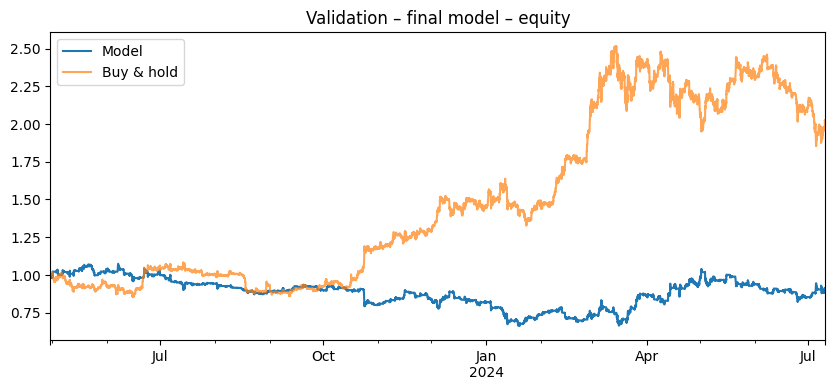

=== Validation – best-on-val model ===
  Candles      : 10,509  (2023-04-29 22:00:00+00:00 → 2024-07-10 18:00:00+00:00)
  Model return : -48.08%
  Buy & hold   : +98.28%   (max DD -26.30%)
  Sharpe       : -1.27
  Max drawdown : -57.91%
  Trades       : 276   | total cost paid: 36.00%
  Time flat/long/short: 34% / 31% / 35%
  --- Profit on $10,000 ---
  Gain before fees : $-2,086
  Trading fees     : $-2,722
  NET PROFIT       : $-4,808   (final value $5,192)


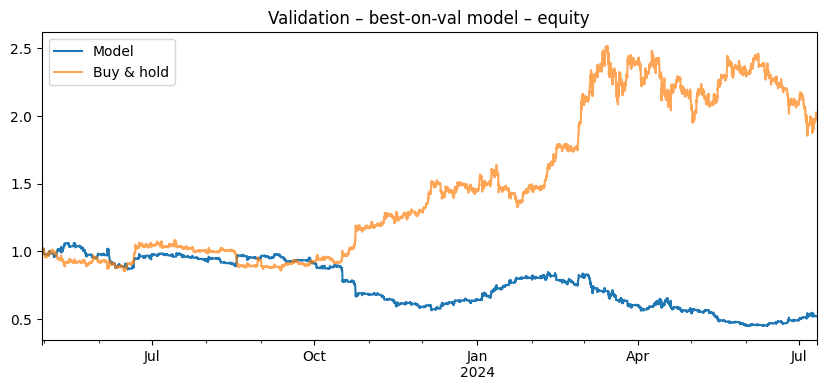

In [105]:
val_df = pd.read_parquet("data/val.parquet")

eq_final = backtest("artifacts/ppo_final", "artifacts/vecnormalize.pkl",
                    val_df, label="Validation – final model")

eq_best = backtest("artifacts/best/best_model", "artifacts/best/vecnormalize.pkl",
                   val_df, label="Validation – best-on-val model")

In [106]:
#final test

=== TEST – best-on-val model ===
  Candles      : 10,510  (2024-07-13 07:00:00+00:00 → 2025-09-24 04:00:00+00:00)
  Model return : -11.52%
  Buy & hold   : +93.39%   (max DD -31.29%)
  Sharpe       : -0.07
  Max drawdown : -36.39%
  Trades       : 277   | total cost paid: 37.00%
  Time flat/long/short: 33% / 32% / 35%
  --- Profit on $10,000 ---
  Gain before fees : $+2,859
  Trading fees     : $-4,012
  NET PROFIT       : $-1,152   (final value $8,848)


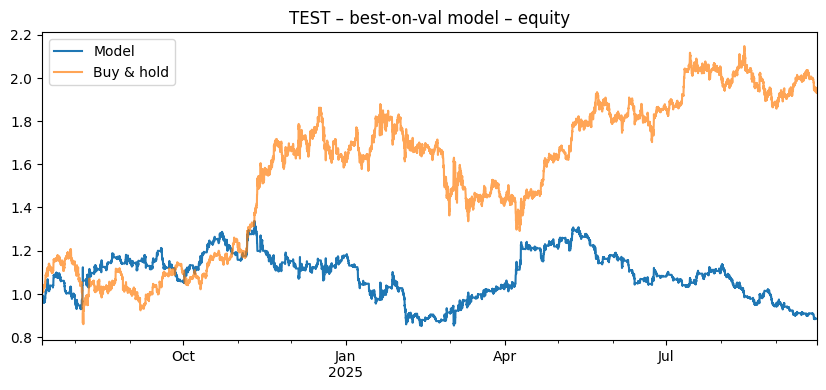

In [107]:
test_df = pd.read_parquet("data/test.parquet")

eq_test = backtest("artifacts/best/best_model", "artifacts/best/vecnormalize.pkl",
                   test_df, label="TEST – best-on-val model", mode="test")

In [108]:
def run_fixed(df, action):
    env = TradingEnv(df, episode_len=len(df) - LOOKBACK - 1, mode="validation")
    env.reset()
    done = False
    while not done:
        _, _, te, tr, info = env.step(action)
        done = te or tr
    return info["equity"] - 1

print("always flat:", f"{run_fixed(val_df, 0):+.2%}")
print("always long:", f"{run_fixed(val_df, 1):+.2%}")

always flat: +0.00%
always long: +98.08%


In [109]:
def rule_backtest(df, pos, cost_bps=10.0):
    """pos[t] in {-1,0,1} is decided at the CLOSE of candle t and earns candle t+1
       (same timing and same fee rule as TradingEnv: fee = cost * |change in position|)."""
    pos = np.asarray(pos, dtype=float)
    mkt = np.expm1(df["log_ret_1"].to_numpy())            # simple return of each candle
    p_prev = np.concatenate([[0.0], pos[:-1]])
    fee = (cost_bps / 10_000) * np.abs(pos - p_prev)
    step_ret = pos[:-1] * mkt[1:] - fee[:-1]               # position at t earns candle t+1
    eq = np.concatenate([[1.0], np.cumprod(1.0 + step_ret)])
    trades = int((np.abs(pos - p_prev) > 0).sum())
    dd = (eq / np.maximum.accumulate(eq) - 1).min()
    s = pd.Series(eq, index=df.index[:len(eq)])
    daily = s.resample("1D").last().dropna().pct_change().dropna()
    sharpe = np.sqrt(365) * daily.mean() / (daily.std() + 1e-9)
    return dict(ret=eq[-1] - 1, trades=trades, maxdd=dd, sharpe=sharpe)

def compare_rules(df, name):
    c = df["close"]
    rows = {}
    rows["Always flat"]  = rule_backtest(df, np.zeros(len(df)))
    rows["Buy & hold"]   = rule_backtest(df, np.ones(len(df)))
    for hrs in (24, 72, 168, 336):                         # 1 day, 3 days, 1 week, 2 weeks
        n = max(int(round(hrs * BARS_PER_HOUR)), 1)
        ema = c.ewm(span=n, adjust=False).mean()
        above = (c > ema).to_numpy()
        rows[f"Trend long-only  ({hrs}h)"] = rule_backtest(df, np.where(above, 1, 0))
        rows[f"Trend long/short ({hrs}h)"] = rule_backtest(df, np.where(above, 1, -1))
    out = pd.DataFrame(rows).T
    out["ret"] = (out["ret"] * 100).round(1)
    out["maxdd"] = (out["maxdd"] * 100).round(1)
    out["sharpe"] = out["sharpe"].round(2)
    out = out.rename(columns={"ret": "return %", "maxdd": "max drawdown %"})
    print(f"\n===== {name} =====")
    print(out.to_string())
    return out

train_df = pd.read_parquet("data/train.parquet")
val_df   = pd.read_parquet("data/val.parquet")
_ = compare_rules(train_df, "TRAIN")
_ = compare_rules(val_df,   "VALIDATION")


===== TRAIN =====
                         return %  trades  max drawdown %  sharpe
Always flat                   0.0     0.0             0.0    0.00
Buy & hold                  582.7     1.0           -83.9    0.83
Trend long-only  (24h)      -99.2  6015.0           -99.6   -1.19
Trend long/short (24h)     -100.0  6016.0          -100.0   -2.50
Trend long-only  (72h)      118.2  2855.0           -75.6    0.53
Trend long/short (72h)      -93.4  2856.0           -95.5   -0.20
Trend long-only  (168h)     554.9  1819.0           -63.7    0.90
Trend long/short (168h)     -41.2  1820.0           -78.4    0.28
Trend long-only  (336h)     464.8  1241.0           -64.0    0.85
Trend long/short (336h)     -55.8  1242.0           -87.1    0.23

===== VALIDATION =====
                         return %  trades  max drawdown %  sharpe
Always flat                   0.0     0.0             0.0    0.00
Buy & hold                   98.6     1.0           -26.3    1.53
Trend long-only  (24h)      -60.6